# Unified Mesh Construction (Uniform Mesh + Adaptive Quadtree Mesh)

This script integrates `normalMesh.ipynb` and `adaptiveMesh.ipynb`: with a **manually settable overall extent**, it builds both meshes in one pass and outputs four distance-vector files:

| File | Content |
| ---- | ---- |
| `shf_with_distance_vectors.pkl` | df_SHF raw data + distance vectors to **adaptive mesh** centers |
| `shf_with_distance_vectors_normal.pkl` | df_SHF raw data + distance vectors to **uniform mesh** centers |
| `geo_with_distance_vectors.pkl` | df_GEO raw data + distance vectors to **adaptive mesh** centers |
| `geo_with_distance_vectors_normal.pkl` | df_GEO raw data + distance vectors to **uniform mesh** centers |

**Main steps**
1. Set the overall mesh extent (start/end lon-lat) and various parameters (see the "Global Configuration" cell).
2. Load df_SHF and df_GEO, unify the lon/lat column names, and clip to the set extent.
3. Extract the **specified target columns** from df_GEO and normalize them (Standard → MinMax) for variance computation.
4. Build the **uniform mesh** (regular 0.2°×0.2° cells tiled over the set extent).
5. Based on the target-column variance and df_SHF point distribution, build the **adaptive mesh** by automatic quadtree subdivision.
6. Compute the distance vectors from each df_SHF/df_GEO point to the centers of both meshes and save them pairwise as four files.


In [1]:
# ==================== Import dependencies ====================
import os
import sys
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import pyproj; pyproj.datadir.set_data_dir(r'C:\Users\19023\anaconda3\envs\KanSHF\Library\share\proj')

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.base import BaseEstimator, TransformerMixin

plt.rcParams['font.family'] = ['Times New Roman', 'FangSong', 'SimHei', 'Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False

# Ensure the quadtree module can be imported (with support for the new parameters)
if 'quadtree_mesh' in sys.modules:
    del sys.modules['quadtree_mesh']
sys.path.insert(0, '.')
import quadtree_mesh
importlib.reload(quadtree_mesh)
from quadtree_mesh import build_quadtree, points_in_bbox

print("依赖导入完成")


c:\Users\19023\anaconda3\envs\KanSHF\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


依赖导入完成


In [2]:
# ==================== Global configuration ====================
# ==================== 1. Manually set the overall mesh extent (start / end lon-lat) ====================
LON_MIN = 112.9   # start longitude (westernmost)
LON_MAX = 123.1   # end longitude (easternmost)
LAT_MIN = 23.1    # start latitude (southernmost)
LAT_MAX = 39.3    # end latitude (northernmost)

# ==================== 2. Uniform mesh parameters ====================
lon_step = 0.2    # uniform mesh longitude step (degrees)
lat_step = 0.2    # uniform mesh latitude step (degrees)

# ==================== 3. Adaptive mesh (quadtree) parameters ====================
# Target geological columns used for normalization and variance computation (only these columns are counted)
TARGET_COLS = [
    'Magnetic_Anomaly_Value(nT)', 'DEM', 'RASTERVALU',
    'cpd', 'LAB', 'Thermal Conductivity （mW/K/m/）', 'H(km)', 'DTF',
    'crsthk', 'sedthk-m', 'bd6', 'bd7', 'bd8', 'bd9', 'ro6', 'ro7', 'ro8', 'ro9', 'vp6', 'vp7', 'vp8', 'vp9', 'vs6', 'vs7', 'vs8', 'vs9',
    'DTR'
]
max_depth     = 8     # maximum quadtree subdivision depth
min_size      = 0.2   # minimum cell size (degrees); cells smaller than this are not subdivided further
point_thresh  = 3     # subdivide further if the number of SHF points in a cell > this value
var_factor    = 0.1   # variance threshold = global variance × this factor (smaller = more sensitive)

# ==================== 4. Output settings ====================
clip_to_range = True    # True: keep only points within the set extent for distance computation; False: keep all raw points
OUTPUT_DIR    = '../output/model/mesh'
file_prefix   = ''      # output filename prefix (leave empty for the same naming as the example)


In [3]:
# ==================== Load data ====================
df_SHF = pd.read_excel('../output/interpolated_to_SHF.xlsx')   # surface heat flow data
df_GEO = pd.read_excel('../output/grid_0.2deg.xlsx')   # geological datasets

# Unify the lon/lat column names to Lon / Lat
for df in (df_SHF, df_GEO):
    if 'Lon' not in df.columns and 'Longitude' in df.columns:
        df.rename(columns={'Longitude': 'Lon', 'Latitude': 'Lat'}, inplace=True)

print("df_SHF:", df_SHF.shape, "->", df_SHF.columns.tolist())
print("df_GEO:", df_GEO.shape, "->", df_GEO.columns.tolist())

# Validate that the target columns exist
missing = [c for c in TARGET_COLS if c not in df_GEO.columns]
if missing:
    raise ValueError(f"TARGET_COLS 中以下列在 df_GEO 中不存在: {missing}")
print(f"✓ TARGET_COLS 校验通过，共 {len(TARGET_COLS)} 列")


df_SHF: (703, 31) -> ['数据编号', 'Lon', 'Lat', 'SHF__mW_m2_', 'Magnetic_Anomaly_Value(nT)', 'DEM', 'RASTERVALU', 'cpd', 'LAB', 'Thermal Conductivity （mW/K/m/）', 'crsthk', 'sedthk-m', 'bd6', 'bd7', 'bd8', 'bd9', 'ro6', 'ro7', 'ro8', 'ro9', 'vp6', 'vp7', 'vp8', 'vp9', 'vs6', 'vs7', 'vs8', 'vs9', 'H(km)', 'DTF', 'DTR']
df_GEO: (4131, 29) -> ['Lat', 'Lon', 'Magnetic_Anomaly_Value(nT)', 'DEM', 'RASTERVALU', 'cpd', 'LAB', 'Thermal Conductivity （mW/K/m/）', 'crsthk', 'sedthk-m', 'bd6', 'bd7', 'bd8', 'bd9', 'ro6', 'ro7', 'ro8', 'ro9', 'vp6', 'vp7', 'vp8', 'vp9', 'vs6', 'vs7', 'vs8', 'vs9', 'H(km)', 'DTF', 'DTR']
✓ TARGET_COLS 校验通过，共 27 列


In [4]:
# ==================== Clip data to the set extent ====================
def filter_to_range(df, lon_min, lon_max, lat_min, lat_max):
    mask = (df['Lon'] >= lon_min) & (df['Lon'] <= lon_max) & \
           (df['Lat'] >= lat_min) & (df['Lat'] <= lat_max)
    return df[mask].copy().reset_index(drop=True)

df_SHF_range = filter_to_range(df_SHF, LON_MIN, LON_MAX, LAT_MIN, LAT_MAX)
df_GEO_range = filter_to_range(df_GEO, LON_MIN, LON_MAX, LAT_MIN, LAT_MAX)

print(f"设定范围: Lon [{LON_MIN}, {LON_MAX}], Lat [{LAT_MIN}, {LAT_MAX}]")
print(f"范围内 SHF 点: {len(df_SHF_range)} / {len(df_SHF)}")
print(f"范围内 GEO 点: {len(df_GEO_range)} / {len(df_GEO)}")

# ==================== Normalize target columns (Standard → MinMax) ====================
class StandardThenMinMaxScaler(BaseEstimator, TransformerMixin):
    def __init__(self):
        self.standard_scaler = StandardScaler()
        self.minmax_scaler = MinMaxScaler()

    def fit(self, X, y=None):
        X_std = self.standard_scaler.fit_transform(X)
        self.minmax_scaler.fit(X_std)
        return self

    def transform(self, X):
        return self.minmax_scaler.transform(self.standard_scaler.transform(X))

    def inverse_transform(self, X):
        return self.standard_scaler.inverse_transform(self.minmax_scaler.inverse_transform(X))

df_to_scale = df_GEO_range[TARGET_COLS].copy()
df_to_scale = df_to_scale.fillna(df_to_scale.mean())   # fill missing values with the column mean
scaler = StandardThenMinMaxScaler()
scaled_values = scaler.fit_transform(df_to_scale)

df_GEO_scaled = df_GEO_range.copy()
df_GEO_scaled[TARGET_COLS] = scaled_values

print("✓ 目标列归一化完成")
print(df_GEO_scaled[TARGET_COLS].head(3))


设定范围: Lon [112.9, 123.1], Lat [23.1, 39.3]
范围内 SHF 点: 703 / 703
范围内 GEO 点: 4131 / 4131
✓ 目标列归一化完成
   Magnetic_Anomaly_Value(nT)       DEM  RASTERVALU       cpd       LAB  \
0                    0.433474  0.171849    0.465966  0.363630  0.085588   
1                    0.433474  0.405884    0.465966  0.353525  0.083513   
2                    0.418109  0.405884    0.553709  0.341895  0.080054   

   Thermal Conductivity （mW/K/m/）     H(km)       DTF    crsthk  sedthk-m  \
0                        0.654367  0.355396  0.067089  0.600910  0.009544   
1                        0.677895  0.357130  0.054691  0.595478  0.011014   
2                        0.696886  0.361208  0.033746  0.590665  0.012871   

   ...       ro9       vp6       vp7       vp8       vp9       vs6       vs7  \
0  ...  0.722871  0.911108  0.128978  0.030045  0.768034  0.940743  0.135199   
1  ...  0.705150  0.911230  0.129482  0.030903  0.756366  0.940744  0.135409   
2  ...  0.688498  0.911692  0.134142  0.030905  0.74

In [5]:
# ==================== Build the uniform mesh ====================
# Tile a regular grid within the set extent; the center of each cell is the unit center
lons = np.arange(LON_MIN + lon_step / 2, LON_MAX, lon_step)
lats = np.arange(LAT_MIN + lat_step / 2, LAT_MAX, lat_step)

mesh_data = []
for lon in lons:
    for lat in lats:
        mesh_data.append({
            'xmin':     lon - lon_step / 2,
            'ymin':     lat - lat_step / 2,
            'xmax':     lon + lon_step / 2,
            'ymax':     lat + lat_step / 2,
            'width':    lon_step,
            'height':   lat_step,
            'center_x': lon,
            'center_y': lat,
        })
mesh_uniform = pd.DataFrame(mesh_data)

print(f"均匀网格单元数: {len(mesh_uniform)}  ({len(lons)} × {len(lats)})")
print(mesh_uniform.head())


均匀网格单元数: 4131  (51 × 81)
    xmin  ymin   xmax  ymax  width  height  center_x  center_y
0  112.9  23.1  113.1  23.3    0.2     0.2     113.0      23.2
1  112.9  23.3  113.1  23.5    0.2     0.2     113.0      23.4
2  112.9  23.5  113.1  23.7    0.2     0.2     113.0      23.6
3  112.9  23.7  113.1  23.9    0.2     0.2     113.0      23.8
4  112.9  23.9  113.1  24.1    0.2     0.2     113.0      24.0


In [6]:
# ==================== Build the adaptive mesh (automatic quadtree subdivision) ====================
# Same subdivision logic as the example: subdivide based on target-column variance + df_SHF point distribution
mesh_leaves = build_quadtree(
    df_shf=df_SHF_range,
    df_geo=df_GEO_scaled,
    max_depth=max_depth,
    min_size=min_size,
    point_thresh=point_thresh,
    var_factor=var_factor,
    geo_cols=TARGET_COLS,                          # compute variance using only the target columns
    bounds=(LON_MIN, LAT_MIN, LON_MAX, LAT_MAX),   # manually set overall extent
)
mesh_adaptive = pd.DataFrame(mesh_leaves).sort_values(['depth', 'cell_id']).reset_index(drop=True)

print(f"自适应网格单元数: {len(mesh_adaptive)}")
print(f"深度范围: {mesh_adaptive['depth'].min()} - {mesh_adaptive['depth'].max()}")
print(f"SHF 点数范围: {mesh_adaptive['n_points'].min()} - {mesh_adaptive['n_points'].max()}")
print(mesh_adaptive.head())


自适应网格单元数: 625
深度范围: 3 - 6
SHF 点数范围: 0 - 10
  cell_id     xmin    ymin     xmax    ymax  center_x  center_y  width  \
0      10  121.825  35.250  123.100  37.275  122.4625   36.2625  1.275   
1     106  121.825  31.200  123.100  33.225  122.4625   32.2125  1.275   
2     107  120.550  33.225  121.825  35.250  121.1875   34.2375  1.275   
3     108  121.825  33.225  123.100  35.250  122.4625   34.2375  1.275   
4      12  121.825  37.275  123.100  39.300  122.4625   38.2875  1.275   

   height  depth  n_points   geo_var  n_geo_cells  
0   2.025      3         3  0.001650           60  
1   2.025      3         3  0.002117           60  
2   2.025      3         0  0.002056           70  
3   2.025      3         0  0.001816           60  
4   2.025      3         1  0.002115           60  


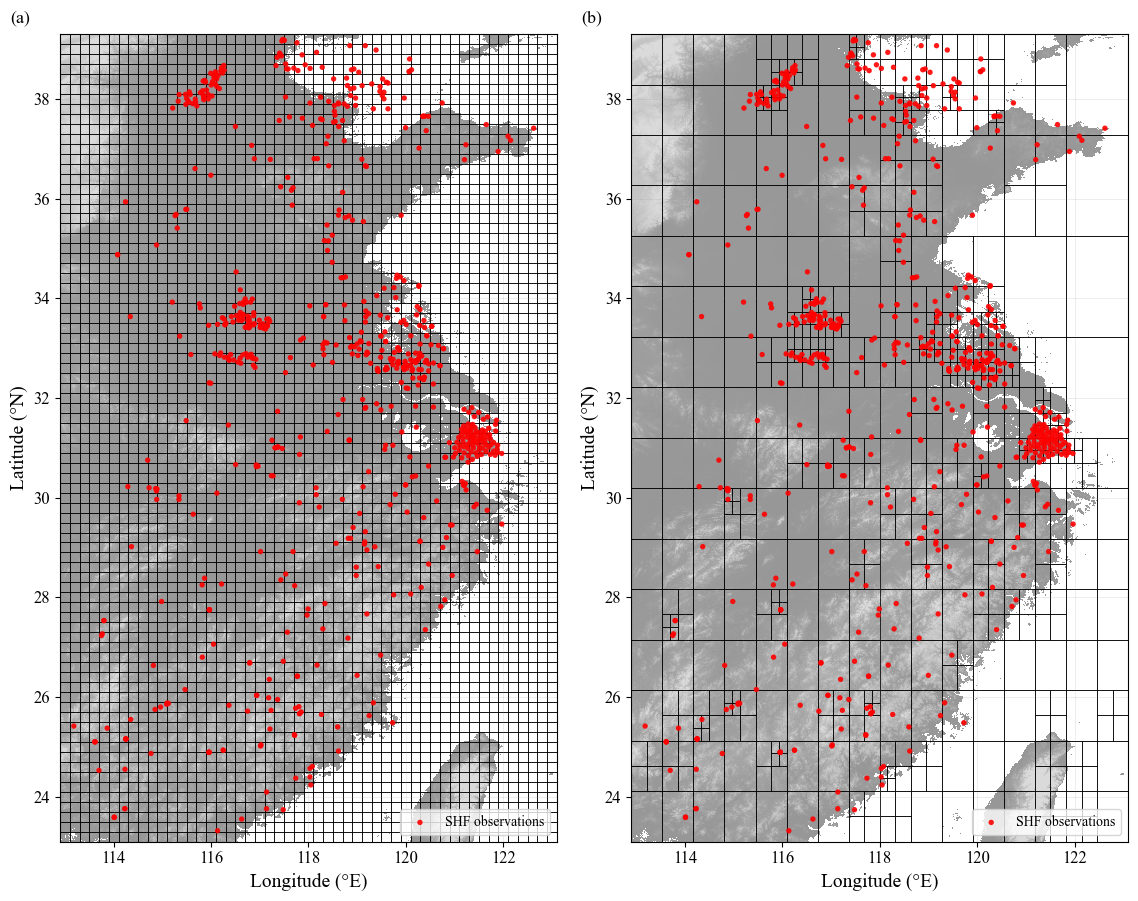

In [7]:
# ==================== Mesh visualization (plain matplotlib, not cartopy/pygmt) ====================
# (Optional) Load the East China outline
gdf = None
plot_shapefile_boundary = None
shapefile_path = '../data/eastChinaLine.shp'
try:
    import geopandas as gpd
    gdf = gpd.read_file(shapefile_path)
    if gdf.crs != 'EPSG:4326':
        gdf = gdf.to_crs('EPSG:4326')

    def plot_shapefile_boundary(ax, gdf, color='none', linewidth=1.5):
        for geom in gdf.geometry:
            if geom.is_empty:
                continue
            geom_to_plot = geom.boundary if geom.geom_type in ['Polygon', 'MultiPolygon'] else geom
            if geom_to_plot.geom_type == 'LineString':
                x, y = zip(*geom_to_plot.coords)
                ax.plot(x, y, color=color, linewidth=linewidth)
            elif geom_to_plot.geom_type == 'MultiLineString':
                for line in geom_to_plot.geoms:
                    x, y = zip(*line.coords)
                    ax.plot(x, y, color=color, linewidth=linewidth)
except Exception as e:
    print(f"加载 shapefile 失败: {e}，跳过轮廓绘制")

def plot_mesh(ax, mesh_df, color='black'):
    for _, row in mesh_df.iterrows():
        _x0, _y0 = row['xmin'], row['ymin']
        _w, _h = row['width'], row['height']
        # pure black grid lines (no edge, thin)
        ax.add_patch(Rectangle((_x0, _y0), _w, _h, linewidth=0.5, edgecolor=color,
                               facecolor='none', alpha=1.0))

# ===== pygmt high-resolution terrain basemap (SRTM15+, 15s≈460m; downloaded on first run and cached locally) =====
import os as _os
_env_root = r'C:\Users\19023\anaconda3\envs\KanSHF'
_os.environ['GDAL_DRIVER_PATH'] = _env_root + r'\Library\lib\gdalplugins'
_os.environ['PATH'] = (_env_root + r'\Library\bin' + _os.pathsep +
                       _env_root + r'\Library\lib\gdalplugins' + _os.pathsep +
                       _os.environ.get('PATH', ''))
# Fix the GMT temp-directory issue (TMPDIR/TEMP/TMP may be invalid in a long-lived kernel)
_tmpdir = r'C:\Users\19023\AppData\Local\Temp'
_os.makedirs(_tmpdir, exist_ok=True)
for _k in ('TMPDIR', 'TEMP', 'TMP'):
    _os.environ[_k] = _tmpdir
import pygmt
import matplotlib.colors as mcolors

_relief = pygmt.datasets.load_earth_relief(
    resolution='15s', region=[LON_MIN, LON_MAX, LAT_MIN, LAT_MAX], registration=None)
_lon_mesh, _lat_mesh = np.meshgrid(_relief.lon.values, _relief.lat.values)
_dem_grid = _relief.values.astype(float)

# Gray-white terrain basemap: sea (≤0) pure white; land (>0) gray → white (grayscale, clear coastline boundary)
class GrayTerrainNorm(mcolors.Normalize):
    def __init__(self, vland=1500.0, gray_lo=0.5, gray_hi=0.75):
        self.vland, self.gray_lo, self.gray_hi = vland, gray_lo, gray_hi
        super().__init__(vmin=0.0, vmax=vland)
    def __call__(self, value, clip=None):
        v = np.ma.asarray(value, dtype=float)
        out = np.ma.masked_all_like(v)
        sea = v <= 0
        land = v > 0
        if np.any(sea):
            out[sea] = 1.0   # pure white below sea level
        if np.any(land):
            out[land] = self.gray_lo + np.clip(v[land] / self.vland, 0.0, 1.0) * (self.gray_hi - self.gray_lo)
        return out

_terrain_norm = GrayTerrainNorm()

fig, axes = plt.subplots(1, 2, figsize=(12, 9.5))

for ax, mesh_df, sub_label in [
    (axes[0], mesh_uniform, '(a)'),
    (axes[1], mesh_adaptive, '(b)'),
]:
    ax.pcolormesh(_lon_mesh, _lat_mesh, _dem_grid,
                  cmap='Greys_r', norm=_terrain_norm,
                  zorder=0, shading='auto')   # gray-white terrain basemap
    plot_mesh(ax, mesh_df, 'black')
    ax.scatter(df_SHF_range['Lon'], df_SHF_range['Lat'],
               c='red', s=15, alpha=0.9, edgecolors='none',
               label='SHF observations', zorder=4)
    if gdf is not None and plot_shapefile_boundary is not None:
        plot_shapefile_boundary(ax, gdf)
    # subplot label: top-left outside the axes
    ax.text(-0.1, 1.01, sub_label, transform=ax.transAxes,
            ha='left', va='bottom', fontsize=13)
    ax.set_xlabel('Longitude (°E)', fontsize=14)
    ax.set_ylabel('Latitude (°N)', fontsize=14)
    ax.set_xlim(LON_MIN, LON_MAX)
    ax.set_ylim(LAT_MIN, LAT_MAX)
    ax.grid(True, alpha=0.3, color='0.6', linewidth=0.4)
    ax.tick_params(axis='both', labelsize=12)
    ax.legend(fontsize=10, loc='lower right', framealpha=0.8)

# Explicit layout: reserve label margins, keep the two subplots compact
fig.subplots_adjust(bottom=0.11, left=0.09, top=0.96, right=0.98, wspace=0.15)
import os as _os2
_os2.makedirs('../output/fig/mesh', exist_ok=True)
plt.savefig('../output/fig/mesh/unified_mesh_comparison.png', dpi=1000, bbox_inches='tight')
plt.show()


In [8]:
# ==================== Detailed mesh feature analysis ====================
print("=" * 70)
print("四叉树网格详细分析")
print("=" * 70)

# Distribution by depth
print("\n按网格深度的分布：")
depth_stats = mesh_adaptive.groupby('depth').agg({
    'cell_id': 'count',
    'n_points': ['sum', 'mean', 'max'],
    'geo_var': ['mean', 'min', 'max'],
    'n_geo_cells': ['sum', 'mean']
}).round(4)
print(depth_stats)

# Point concentration analysis
print("\n\nSHF点集中度分析：")
print(f"包含SHF点的网格数: {(mesh_adaptive['n_points'] > 0).sum()} / {len(mesh_adaptive)}")
print(f"平均每个网格内的点数: {mesh_adaptive['n_points'].mean():.2f}")
print(f"点数最多的网格: {mesh_adaptive['n_points'].max()} 个点")

# Geological data coverage analysis
print("\n\n地质数据覆盖分析：")
print(f"有地质数据覆盖的网格数: {(mesh_adaptive['n_geo_cells'] > 0).sum()} / {len(mesh_adaptive)}")
print(f"平均每个网格内的地质网格数: {mesh_adaptive['n_geo_cells'].mean():.2f}")

# Subdivision decision statistics
print("\n\n网格细分统计（各深度网格数）：")
for depth in sorted(mesh_adaptive['depth'].unique()):
    print(f"  深度 {depth}: {len(mesh_adaptive[mesh_adaptive['depth'] == depth]):4d} 个网格")

print("\n" + "=" * 70)


四叉树网格详细分析

按网格深度的分布：
      cell_id n_points             geo_var                 n_geo_cells  \
        count      sum    mean max    mean     min     max         sum   
depth                                                                    
3           6        9  1.5000   3  0.0020  0.0017  0.0023         370   
4         152      117  0.7697   3  0.0017  0.0005  0.0032        2438   
5         271      206  0.7601   3  0.0008  0.0000  0.0031        1127   
6         196      371  1.8929  10  0.0001  0.0000  0.0008         196   

                
          mean  
depth           
3      61.6667  
4      16.0395  
5       4.1587  
6       1.0000  


SHF点集中度分析：
包含SHF点的网格数: 317 / 625
平均每个网格内的点数: 1.12
点数最多的网格: 10 个点


地质数据覆盖分析：
有地质数据覆盖的网格数: 585 / 625
平均每个网格内的地质网格数: 6.61


网格细分统计（各深度网格数）：
  深度 3:    6 个网格
  深度 4:  152 个网格
  深度 5:  271 个网格
  深度 6:  196 个网格



In [9]:
# ==================== Validate mesh integrity and coverage ====================
print("=" * 70)
print("网格覆盖验证")
print("=" * 70)

print(f"\n设定范围：")
print(f"  Longitude: [{LON_MIN:.2f}, {LON_MAX:.2f}]")
print(f"  Latitude:  [{LAT_MIN:.2f}, {LAT_MAX:.2f}]")

# Check the root cell
root_cells = mesh_adaptive[mesh_adaptive['depth'] == 0]
if len(root_cells) > 0:
    root = root_cells.iloc[0]
    print(f"\n根网格覆盖范围：")
    print(f"  Longitude: [{root['xmin']:.2f}, {root['xmax']:.2f}]")
    print(f"  Latitude:  [{root['ymin']:.2f}, {root['ymax']:.2f}]")

# Check whether all SHF points are covered
shf_coverage = 0
for _, row in mesh_adaptive.iterrows():
    count = len(points_in_bbox(df_SHF_range, (row['xmin'], row['ymin'], row['xmax'], row['ymax'])))
    shf_coverage += count
print(f"\nSHF点覆盖率: {shf_coverage}/{len(df_SHF_range)} ({shf_coverage/len(df_SHF_range)*100:.1f}%)")

# Cell count per depth
print(f"\n各层网格数量分布：")
for depth in sorted(mesh_adaptive['depth'].unique()):
    count = len(mesh_adaptive[mesh_adaptive['depth'] == depth])
    print(f"  深度 {depth}: {count:4d} 个网格")

print("\n" + "=" * 70)


网格覆盖验证

设定范围：
  Longitude: [112.90, 123.10]
  Latitude:  [23.10, 39.30]

SHF点覆盖率: 703/703 (100.0%)

各层网格数量分布：
  深度 3:    6 个网格
  深度 4:  152 个网格
  深度 5:  271 个网格
  深度 6:  196 个网格



In [10]:
# ==================== Detailed per-cell geological statistics + high-density cell report ====================
print("=" * 100)
print("网格地质数据详细统计")
print("=" * 100)

geo_cols = TARGET_COLS
print(f"\n地质数据类型（目标列）：{geo_cols}")
print(f"共有 {len(geo_cols)} 种地质属性\n")

# Compute geological statistics for each cell
detailed_stats = []
for idx, (_, mesh_row) in enumerate(mesh_adaptive.iterrows()):
    bbox = (mesh_row['xmin'], mesh_row['ymin'], mesh_row['xmax'], mesh_row['ymax'])
    geo_subset = points_in_bbox(df_GEO_range, bbox)

    if len(geo_subset) > 0:
        row_data = {
            'cell_id': mesh_row['cell_id'],
            'depth': mesh_row['depth'],
            'center_lon': mesh_row['center_x'],
            'center_lat': mesh_row['center_y'],
            'xmin': mesh_row['xmin'],
            'ymin': mesh_row['ymin'],
            'xmax': mesh_row['xmax'],
            'ymax': mesh_row['ymax'],
            'width': mesh_row['width'],
            'height': mesh_row['height'],
            'n_geo_cells': len(geo_subset),
            'n_shf_points': mesh_row['n_points'],
        }
        for col in geo_cols:
            valid_data = geo_subset[col].dropna()
            if len(valid_data) > 0:
                row_data[f'{col}_min'] = valid_data.min()
                row_data[f'{col}_max'] = valid_data.max()
                row_data[f'{col}_mean'] = valid_data.mean()
                row_data[f'{col}_std'] = valid_data.std()
                row_data[f'{col}_count'] = len(valid_data)
            else:
                for suffix in ('min', 'max', 'mean', 'std'):
                    row_data[f'{col}_{suffix}'] = np.nan
                row_data[f'{col}_count'] = 0
        detailed_stats.append(row_data)

detailed_df = pd.DataFrame(detailed_stats)
print(f"生成了 {len(detailed_df)} 个网格的详细地质数据统计（含地质数据的网格）\n")

# Save the detailed statistics
os.makedirs(OUTPUT_DIR, exist_ok=True)
detailed_csv = os.path.join(OUTPUT_DIR, f'{file_prefix}quadtree_mesh_geological_stats.csv')
detailed_df.to_csv(detailed_csv, index=False)
print(f"✓ 详细地质数据统计已保存到: {detailed_csv}")

# High-density cell report (n_points >= 5)
high_density = detailed_df[detailed_df['n_shf_points'] >= 5].copy()
print(f"\n点数 >= 5 的高密度网格数: {len(high_density)}")
if len(high_density) > 0:
    high_density_report = high_density[[
        'cell_id', 'depth', 'center_lon', 'center_lat', 'n_shf_points', 'n_geo_cells'
    ]].copy()
    high_density_xlsx = os.path.join(OUTPUT_DIR, f'{file_prefix}quadtree_mesh_high_density.xlsx')
    high_density_report.to_excel(high_density_xlsx, index=False, sheet_name='HighDensity')
    print(f"✓ 高密度网格报告已保存到: {high_density_xlsx}")
    print("\nSHF点最密集的前5个网格：")
    print(high_density_report.sort_values('n_shf_points', ascending=False).head(5).to_string(index=False))

print("\n" + "=" * 100)


网格地质数据详细统计

地质数据类型（目标列）：['Magnetic_Anomaly_Value(nT)', 'DEM', 'RASTERVALU', 'cpd', 'LAB', 'Thermal Conductivity （mW/K/m/）', 'H(km)', 'DTF', 'crsthk', 'sedthk-m', 'bd6', 'bd7', 'bd8', 'bd9', 'ro6', 'ro7', 'ro8', 'ro9', 'vp6', 'vp7', 'vp8', 'vp9', 'vs6', 'vs7', 'vs8', 'vs9', 'DTR']
共有 27 种地质属性

生成了 585 个网格的详细地质数据统计（含地质数据的网格）

✓ 详细地质数据统计已保存到: ../output/model/mesh\quadtree_mesh_geological_stats.csv

点数 >= 5 的高密度网格数: 15
✓ 高密度网格报告已保存到: ../output/model/mesh\quadtree_mesh_high_density.xlsx

SHF点最密集的前5个网格：
cell_id  depth  center_lon  center_lat  n_shf_points  n_geo_cells
    133      6  121.267188   31.326563            10            1
    384      6  116.645312   33.604688             9            1
    211      6  119.992188   32.592188             7            1
    475      6  121.585938   31.073437             7            2
    480      6  121.426562   31.073437             7            2



In [11]:
# ==================== Compute the variance threshold and global variance ====================
# Compute the global geological variance from the (already normalized) target columns
global_geo_var = df_GEO_scaled[TARGET_COLS].var(ddof=0).replace({np.nan: 0.0}).mean()
var_thresh = float(global_geo_var * var_factor)

print(f"Global Geological Variance: {global_geo_var:.6f}")
print(f"Variance Threshold (var_factor={var_factor}): {var_thresh:.6f}")
print(f"Number of grids with variance > threshold: {(mesh_adaptive['geo_var'] > var_thresh).sum()}")


Global Geological Variance: 0.032967
Variance Threshold (var_factor=0.1): 0.003297
Number of grids with variance > threshold: 0



Variance Distribution Visualization


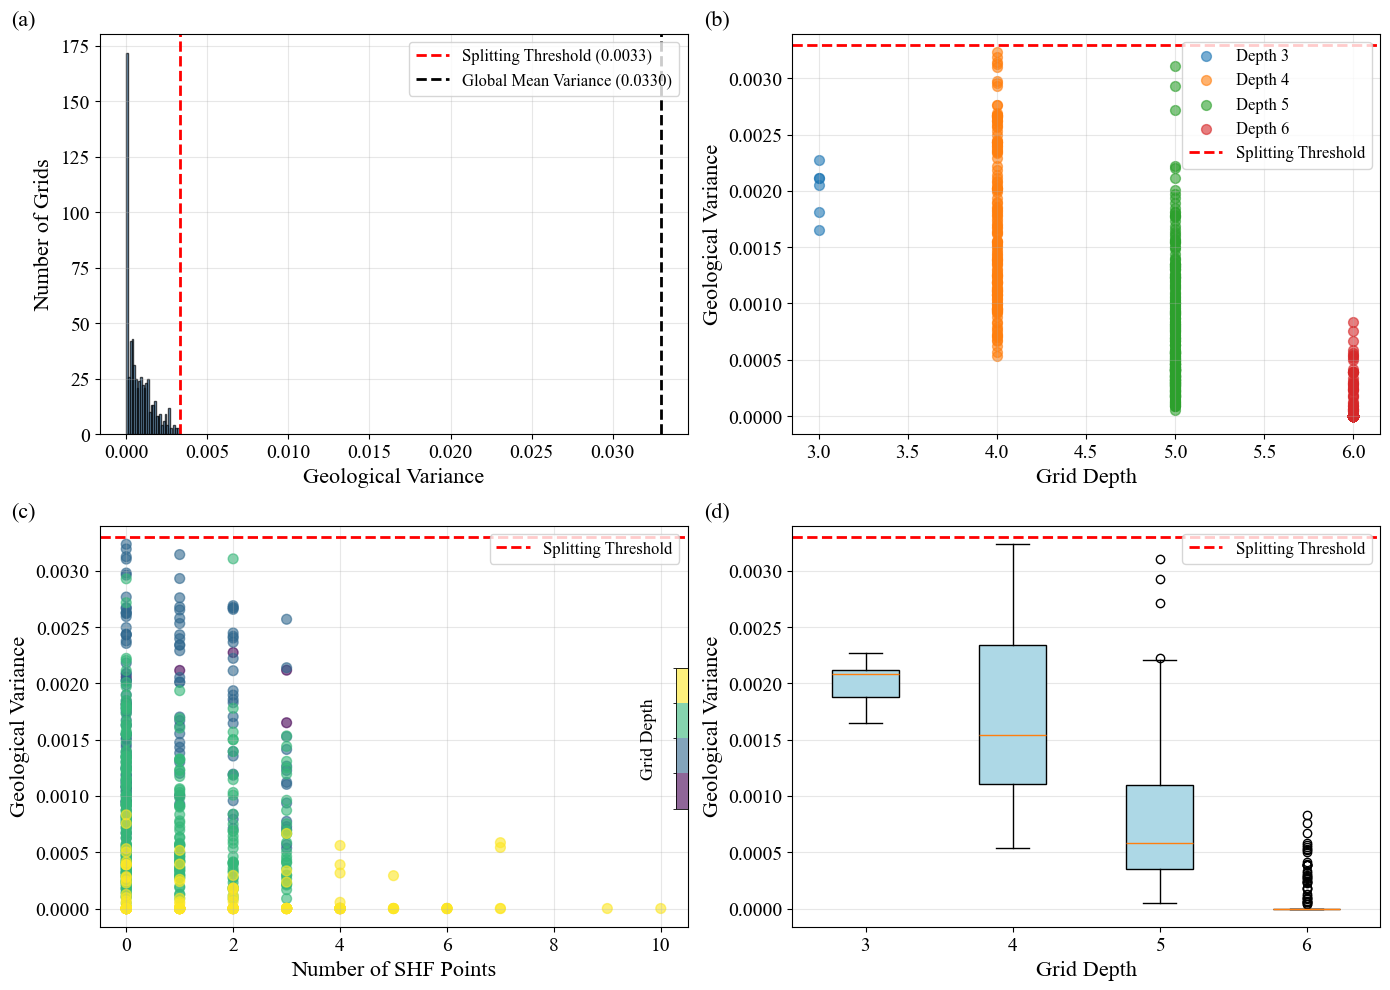

✓ Variance analysis figure saved to: ../output/fig/mesh/variance_analysis.png



In [12]:
# ==================== Variance distribution visualization (2×2 analysis figure) ====================
# Same analysis figure as the example: (a) variance histogram (b) variance vs depth
# (c) variance vs SHF point count (d) boxplot per depth
print("\nVariance Distribution Visualization")
print("=" * 100)

import matplotlib.colors as mcolors

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# ---------- Subplot (a): variance histogram ----------
ax = axes[0, 0]
ax.hist(mesh_adaptive['geo_var'], bins=30, edgecolor='black', alpha=0.7, color='steelblue')
ax.axvline(var_thresh, color='red', linestyle='--', linewidth=2, label=f'Splitting Threshold ({var_thresh:.4f})')
ax.axvline(global_geo_var, color='black', linestyle='--', linewidth=2, label=f'Global Mean Variance ({global_geo_var:.4f})')
ax.set_xlabel('Geological Variance', fontsize=16)
ax.set_ylabel('Number of Grids', fontsize=16)
ax.legend(fontsize=12, loc='upper right')
ax.grid(True, alpha=0.3)
ax.tick_params(axis='both', labelsize=14)
ax.text(-0.15, 1.01, '(a)', transform=ax.transAxes, ha='left', va='bottom', fontsize=16)

# ---------- Subplot (b): variance vs mesh depth ----------
ax = axes[0, 1]
for depth in sorted(mesh_adaptive['depth'].unique()):
    depth_data = mesh_adaptive[mesh_adaptive['depth'] == depth]['geo_var']
    ax.scatter([depth] * len(depth_data), depth_data, alpha=0.6, s=50, label=f'Depth {depth}')
ax.axhline(var_thresh, color='red', linestyle='--', linewidth=2, label='Splitting Threshold')
ax.set_xlabel('Grid Depth', fontsize=16)
ax.set_ylabel('Geological Variance', fontsize=16)
ax.legend(fontsize=12, loc='upper right')
ax.grid(True, alpha=0.3)
ax.tick_params(axis='both', labelsize=14)
ax.text(-0.15, 1.01, '(b)', transform=ax.transAxes, ha='left', va='bottom', fontsize=16)

# ---------- Subplot (c): variance vs SHF point count (colored by depth, small colorbar inside the axes) ----------
ax = axes[1, 0]
_depth_vals = mesh_adaptive['depth']
_dmin, _dmax = _depth_vals.min(), _depth_vals.max()
_levels = np.arange(_dmin, _dmax + 2, 1) - 0.5   # each level = one integer depth
_n_levels = len(_levels) - 1
_cmap_c = plt.get_cmap('viridis', _n_levels)
_norm_c = mcolors.BoundaryNorm(_levels, _n_levels)
scatter = ax.scatter(mesh_adaptive['n_points'], mesh_adaptive['geo_var'],
                     c=_depth_vals, cmap=_cmap_c, norm=_norm_c, s=50, alpha=0.6)
ax.axhline(var_thresh, color='red', linestyle='--', linewidth=2, label='Splitting Threshold')
ax.set_xlabel('Number of SHF Points', fontsize=16)
ax.set_ylabel('Geological Variance', fontsize=16)
# Smaller colorbar: no ticks, placed just inside the right edge of the axes (inset_axes, does not shrink the parent)
_cax = ax.inset_axes([0.98, 0.295, 0.02, 0.35])   # half height (0.7→0.35), keep vertically centered
cbar = plt.colorbar(scatter, cax=_cax, location='left')   # move the label to the left side of the colorbar
cbar.set_label('Grid Depth', fontsize=13, labelpad=8)      # larger font, label renamed to Grid Depth
cbar.ax.set_yticks([])            # no ticks
cbar.outline.set_linewidth(0.6)   # thin outline
ax.legend(fontsize=12, loc='upper right')
ax.grid(True, alpha=0.3)
ax.tick_params(axis='both', labelsize=14)
ax.text(-0.15, 1.01, '(c)', transform=ax.transAxes, ha='left', va='bottom', fontsize=16)

# ---------- Subplot (d): variance boxplot per depth ----------
ax = axes[1, 1]
depth_variances = [mesh_adaptive[mesh_adaptive['depth'] == d]['geo_var'].values
                   for d in sorted(mesh_adaptive['depth'].unique())]
bp = ax.boxplot(depth_variances, tick_labels=sorted(mesh_adaptive['depth'].unique()), patch_artist=True)
for patch in bp['boxes']:
    patch.set_facecolor('lightblue')
ax.axhline(var_thresh, color='red', linestyle='--', linewidth=2, label='Splitting Threshold')
ax.set_xlabel('Grid Depth', fontsize=16)
ax.set_ylabel('Geological Variance', fontsize=16)
ax.legend(fontsize=12, loc='upper right')
ax.grid(True, alpha=0.3, axis='y')
ax.tick_params(axis='both', labelsize=14)
ax.text(-0.15, 1.01, '(d)', transform=ax.transAxes, ha='left', va='bottom', fontsize=16)

plt.tight_layout()
os.makedirs('../output/fig/mesh', exist_ok=True)
plt.savefig('../output/fig/mesh/variance_analysis.png', dpi=300, bbox_inches='tight')
plt.show()
print("✓ Variance analysis figure saved to: ../output/fig/mesh/variance_analysis.png\n")


In [13]:
# ==================== Compute distance vectors and save the four files ====================
os.makedirs(OUTPUT_DIR, exist_ok=True)

def compute_distance_matrix(points_df, centers_df):
    """Compute the Euclidean distance matrix from each data point to all mesh centers."""
    pts = points_df[['Lon', 'Lat']].values
    centers = centers_df[['center_x', 'center_y']].values
    dmat = np.zeros((len(pts), len(centers)))
    for i in range(len(pts)):
        dx = centers[:, 0] - pts[i, 0]
        dy = centers[:, 1] - pts[i, 1]
        dmat[i, :] = np.sqrt(dx ** 2 + dy ** 2)
    return dmat

# Data used for distance computation (optionally clipped to the set extent)
if clip_to_range:
    df_SHF_use, df_GEO_use = df_SHF_range, df_GEO_range
else:
    df_SHF_use, df_GEO_use = df_SHF.copy(), df_GEO.copy()
print(f"距离计算点数: SHF = {len(df_SHF_use)}, GEO = {len(df_GEO_use)}\n")

def attach_and_save(df, centers_df, out_path, tag):
    dmat = compute_distance_matrix(df, centers_df)
    out = df.copy()
    out['distance_vector_to_grids'] = [row.tolist() for row in dmat]
    out.to_pickle(out_path)
    print(f"✓ {tag}: 形状 {out.shape}, 距离向量维度 {dmat.shape[1]}")
    print(f"  -> {out_path}")
    return out

# 1) df_SHF → uniform mesh
df_shf_uniform = attach_and_save(
    df_SHF_use, mesh_uniform,
    os.path.join(OUTPUT_DIR, f'{file_prefix}shf_with_distance_vectors_normal.pkl'),
    'SHF → 均匀网格')
# 2) df_SHF → adaptive mesh
df_shf_adaptive = attach_and_save(
    df_SHF_use, mesh_adaptive,
    os.path.join(OUTPUT_DIR, f'{file_prefix}shf_with_distance_vectors.pkl'),
    'SHF → 自适应网格')
# 3) df_GEO → uniform mesh
df_geo_uniform = attach_and_save(
    df_GEO_use, mesh_uniform,
    os.path.join(OUTPUT_DIR, f'{file_prefix}geo_with_distance_vectors_normal.pkl'),
    'GEO → 均匀网格')
# 4) df_GEO → adaptive mesh
df_geo_adaptive = attach_and_save(
    df_GEO_use, mesh_adaptive,
    os.path.join(OUTPUT_DIR, f'{file_prefix}geo_with_distance_vectors.pkl'),
    'GEO → 自适应网格')

print("\n✅ 四个距离向量文件已保存")


距离计算点数: SHF = 703, GEO = 4131

✓ SHF → 均匀网格: 形状 (703, 32), 距离向量维度 4131
  -> ../output/model/mesh\shf_with_distance_vectors_normal.pkl
✓ SHF → 自适应网格: 形状 (703, 32), 距离向量维度 625
  -> ../output/model/mesh\shf_with_distance_vectors.pkl
✓ GEO → 均匀网格: 形状 (4131, 30), 距离向量维度 4131
  -> ../output/model/mesh\geo_with_distance_vectors_normal.pkl
✓ GEO → 自适应网格: 形状 (4131, 30), 距离向量维度 625
  -> ../output/model/mesh\geo_with_distance_vectors.pkl

✅ 四个距离向量文件已保存


In [14]:
# ==================== Save mesh metadata and summary ====================
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Uniform mesh center points
uniform_centers = mesh_uniform[['center_x', 'center_y']].copy()
uniform_centers.columns = ['center_lon', 'center_lat']
uniform_centers.to_csv(os.path.join(OUTPUT_DIR, f'{file_prefix}normal_mesh_centers.csv'), index=False)

# Adaptive mesh (full cell info + center points)
mesh_adaptive.to_csv(os.path.join(OUTPUT_DIR, f'{file_prefix}quadtree_mesh.csv'), index=False)
adaptive_centers = mesh_adaptive[['cell_id', 'center_x', 'center_y', 'depth', 'n_points']].copy()
adaptive_centers = adaptive_centers.rename(columns={'center_x': 'center_lon', 'center_y': 'center_lat'})
adaptive_centers.to_csv(os.path.join(OUTPUT_DIR, f'{file_prefix}quadtree_mesh_centers.csv'), index=False)

print("✓ 网格元数据已保存")
print(f"  均匀网格: {len(mesh_uniform)} 个单元  -> {file_prefix}normal_mesh_centers.csv")
print(f"  自适应网格: {len(mesh_adaptive)} 个单元 -> {file_prefix}quadtree_mesh.csv / {file_prefix}quadtree_mesh_centers.csv")
print(f"\n所有输出已写入: {OUTPUT_DIR}")


✓ 网格元数据已保存
  均匀网格: 4131 个单元  -> normal_mesh_centers.csv
  自适应网格: 625 个单元 -> quadtree_mesh.csv / quadtree_mesh_centers.csv

所有输出已写入: ../output/model/mesh
